In [2]:
import numpy as np
import pandas as pd
import mne

from neurodsp.filt import filter_signal
from neurodsp.plts import plot_time_series
from neurodsp.sim import sim_combined

from bycycle import Bycycle
from bycycle.cyclepoints import find_extrema, find_zerox
from bycycle.cyclepoints.zerox import find_flank_zerox
from bycycle.plts import plot_cyclepoints_array
from bycycle.utils.download import load_bycycle_data
from bycycle.plts import plot_feature_categorical
from bycycle.utils import flatten_dfs

pd.options.display.max_columns = 10

from scipy import stats

from pathlib import Path

In [3]:
ALL_CHANNELS_26 = [
    'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC3', 'FCz', 'FC4',
    'T7', 'C3', 'Cz', 'C4', 'T8', 'CP3', 'CPz', 'CP4', 'P7', 'P3',
    'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2',
]

# path to the eeg data
EEG_ROOT = Path('/oscar/data/sjones/shared/TDBRAIN_v3/TDBRAIN_Dataset_V3_1')

# path to the meta data - includes info. about age, gender, remitter/responder status
METADATA_PATH = Path('/oscar/data/sjones/shared/TDBRAIN_v3/TDBRAIN_participants_V3.xlsx')

meta = pd.read_excel(METADATA_PATH)

In [4]:
has_remit = meta[meta['Remitter'].notna()].copy()
print(len(has_remit), 'subjects with a remitter value')
print(has_remit['Remitter'].value_counts())

269 subjects with a remitter value
Remitter
1.0    141
0.0    128
Name: count, dtype: int64


In [5]:
has_respond = meta[meta['Responder'].notna()].copy()
print(len(has_respond), 'subjects with a responder value')
print(has_respond['Responder'].value_counts())

273 subjects with a responder value
Responder
1.0    182
0.0     91
Name: count, dtype: int64


In [6]:
# confirming that the eeg files are in the correct folders 
found_ec = []
missing_ec = []

found_eo = []
missing_eo = []

for subj in has_remit['TDBRAIN_ID'].unique(): 
    subj = str(subj)
    folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'

    if folder.exists(): 
        files_ec = list(folder.glob('*restEC*_eeg.npy'))
        files_eo = list(folder.glob('*restEO*_eeg.npy'))
    else: 
        files_ec = []
        files_eo = []
    
    if len(files_ec) > 0: 
        found_ec.append(subj)
    else:
        missing_ec.append(subj)

    if len(files_eo) > 0:
        found_eo.append(subj)
    else:
        missing_eo.append(subj)

print('EC:', len(found_ec), 'found,', len(missing_ec), 'missing')
print('EO:', len(found_eo), 'found,', len(missing_eo), 'missing')

EC: 249 found, 5 missing
EO: 249 found, 5 missing


In [7]:
subj = found_ec[0]

folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'

files = list(folder.glob('*restEC*_eeg.npy'))

data = np.load(files[0])

In [8]:
# loading eyes closed data for each subject 

ec_data = {}
for subj in found_ec: 
    folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'
    files = list(folder.glob('*restEC*_eeg.npy'))

    ec_data[subj] = np.load(files[0])

In [9]:
# loading eyes open data for each subject
eo_data = {}
for subj in found_eo: 
    folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'
    files = list(folder.glob('*restEO*_eeg.npy'))

    eo_data[subj] = np.load(files[0])

In [10]:
has_remit['TDBRAIN_ID'] = has_remit['TDBRAIN_ID'].astype(str)

# TDBRAIN_ID set as a row instead of a column 
labels = has_remit.drop_duplicates(subset='TDBRAIN_ID').set_index('TDBRAIN_ID')

print(labels.loc[found_ec[0], 'Remitter'])
print(labels.loc[found_ec[0], 'Responder'])

1.0
1.0


In [11]:
# bycycle analysis - 3d array (n_channels, n_epochs, n_timepoints)

n_seconds = 5
fs = 500

f_range = (8, 12) # alpha range (but compare to other frequency bands, beta and theta)

n_channels = 26
n_epochs = 17

In [12]:
df_cycles = pd.read_pickle('df_cycles_ec.pkl')
df_cycles['freq'] = fs / df_cycles['period'] # skip if freq was already saved in the file
df_bursts = df_cycles[df_cycles['is_burst'] == True]

print(df_cycles['subject_id'].nunique())   # should be 249
print('freq' in df_cycles.columns)  

249
True


In [13]:
# convert cycle length (in samples) to frequency in Hz, fs is the sampling rate (# of samples per second) / period 
df_cycles['freq'] = fs / df_cycles['period']

# keep only the cycles that are part of a burst
df_bursts = df_cycles[df_cycles['is_burst'] == True]

print(df_bursts.columns)

Index(['amp_fraction', 'amp_consistency', 'period_consistency', 'monotonicity',
       'period', 'time_peak', 'time_trough', 'volt_peak', 'volt_trough',
       'time_decay', 'time_rise', 'volt_decay', 'volt_rise', 'volt_amp',
       'time_rdsym', 'time_ptsym', 'band_amp', 'sample_peak',
       'sample_last_zerox_decay', 'sample_zerox_decay', 'sample_zerox_rise',
       'sample_last_trough', 'sample_next_trough', 'is_burst', 'subject_id',
       'epoch', 'channel', 'remitter', 'responder', 'freq'],
      dtype='str')


In [14]:
summary = df_bursts.groupby('subject_id')[['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym']].mean()
summary['burst_frac'] = df_cycles.groupby('subject_id')['is_burst'].mean()

summary['remitter'] = labels.loc[summary.index, 'Remitter']
summary['responder'] = labels.loc[summary.index, 'Responder']

print(summary)

              volt_amp     period       freq  time_rdsym  time_ptsym  \
subject_id                                                             
sub-87999321  0.000024  50.580214  10.155937    0.495490    0.515169   
sub-88000181  0.000030  47.281796  10.825160    0.498454    0.518379   
sub-88000313  0.000029  49.625812  10.372711    0.494780    0.510216   
sub-88000489  0.000032  55.086246   9.290944    0.494386    0.511861   
sub-88000533  0.000025  45.948571  10.994598    0.511266    0.574036   
...                ...        ...        ...         ...         ...   
sub-88076401  0.000023  50.772436  10.241701    0.500556    0.500300   
sub-88076445  0.000026  44.254480  11.606173    0.487817    0.514257   
sub-88076849  0.000021  46.630603  11.104028    0.494040    0.514356   
sub-88077525  0.000009  44.531250  11.710094    0.546345    0.509476   
sub-88077569  0.000020  43.276982  11.779248    0.493177    0.511551   

              burst_frac  remitter  responder  
subject_id     

In [15]:
# remitter/non-remitter comparison
remitters = summary[summary['remitter'] == 1]
non_remitters = summary[summary['remitter'] == 0]

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']

print(summary[features_keep].head())
print(df_cycles.shape)
print(df_cycles['subject_id'].value_counts())

              volt_amp     period  time_rdsym  time_ptsym       freq
subject_id                                                          
sub-87999321  0.000024  50.580214    0.495490    0.515169  10.155937
sub-88000181  0.000030  47.281796    0.498454    0.518379  10.825160
sub-88000313  0.000029  49.625812    0.494780    0.510216  10.372711
sub-88000489  0.000032  55.086246    0.494386    0.511861   9.290944
sub-88000533  0.000025  45.948571    0.511266    0.574036  10.994598
(5298044, 30)
subject_id
sub-88059081    43932
sub-88059169    40126
sub-88059261    25393
sub-88077569    24229
sub-88005941    23965
                ...  
sub-88035589    16943
sub-88068885    16685
sub-88044189    15563
sub-88032753    15524
sub-88063713    12557
Name: count, Length: 249, dtype: int64


/tmp/ipykernel_1086334/3187624336.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_1086334/3187624336.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_1086334/3187624336.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_1086334/3187624336.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled

Text(0, 0.5, "['Frequency']")

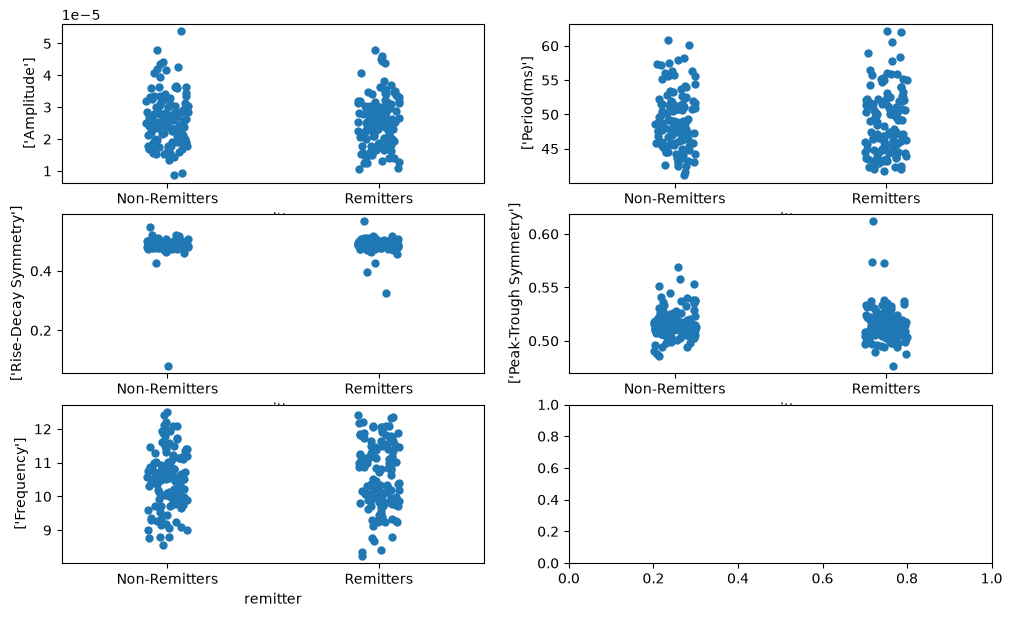

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(12,7))


# amplitude
sns.stripplot(data=summary, x='remitter', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary, x='remitter', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary, x='remitter', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary, x='remitter', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

#freq 
sns.stripplot(data=summary, x='remitter', y='freq', ax=axes[2][0], size=6, jitter=True)
axes[2][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[2][0].set_ylabel(['Frequency'])

In [ ]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry', 
                 'freq': 'Frequency'}

for feat, feat_name in feature_names.items():

    x_remitter = summary[summary['remitter'] == 1][feat].dropna()
    x_non_remitter = summary[summary['remitter'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_remitter, x_non_remitter)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7377, p=0.82099
Period (ms)          difference between groups, U= 7142, p=0.51571
Rise-Decay Symmetry  difference between groups, U= 7004, p=0.36877
Peak-Trough Symmetry difference between groups, U= 7360, p=0.79724
Frequency            difference between groups, U= 7797, p=0.59668


In [18]:
# responder/non-responder comparison 
responders = summary[summary['responder'] == 1]
non_responders = summary[summary['responder'] == 0] 

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']

/tmp/ipykernel_1086334/3650239972.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Responder', 'Responder'])
/tmp/ipykernel_1086334/3650239972.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Responder', 'Responder'])
/tmp/ipykernel_1086334/3650239972.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Responder', 'Responder'])
/tmp/ipykernel_1086334/3650239972.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled

Text(0, 0.5, "['Frequency']")

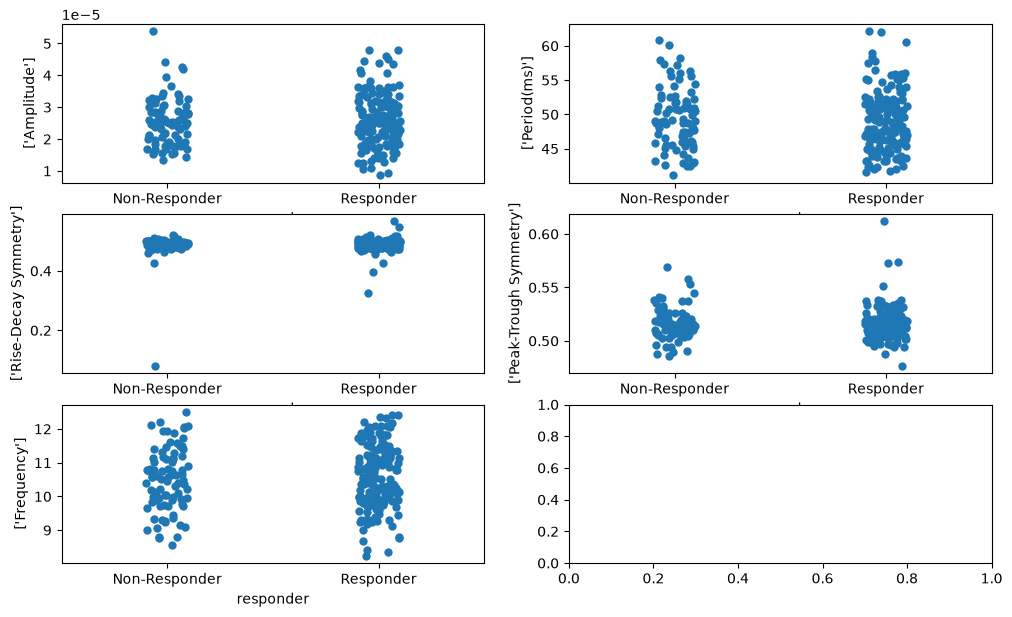

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(12,7))

# amplitude
sns.stripplot(data=summary, x='responder', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Responder', 'Responder'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary, x='responder', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Responder', 'Responder'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary, x='responder', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Responder', 'Responder'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary, x='responder', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Responder', 'Responder'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

#freq
sns.stripplot(data=summary, x='responder', y='freq', ax=axes[2][0], size=6, jitter=True)
axes[2][0].set_xticklabels(['Non-Responder', 'Responder'])
axes[2][0].set_ylabel(['Frequency'])

In [ ]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry',
                 'freq': 'Frequency'}

for feat, feat_name in feature_names.items():
    x_responder = summary[summary['responder'] == 1][feat].dropna()
    x_non_responder = summary[summary['responder'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_responder, x_non_responder)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7196, p=0.45384
Period (ms)          difference between groups, U= 6304, p=0.34803
Rise-Decay Symmetry  difference between groups, U= 6569, p=0.66244
Peak-Trough Symmetry difference between groups, U= 6233, p=0.28332
Frequency            difference between groups, U= 7166, p=0.48880


In [21]:
# eyes open data
df_cycles_eo = pd.read_pickle('df_cycles_eo.pkl')
print(df_cycles_eo['subject_id'].nunique(), len(found_eo))

df_cycles_eo['freq'] = fs / df_cycles_eo['period']
df_bursts_eo = df_cycles_eo[df_cycles_eo['is_burst']]

df_cycles = pd.read_pickle('df_cycles_ec.pkl')

249 249


In [22]:
summary_eo = df_bursts_eo.groupby('subject_id')[['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym']].mean()
summary_eo['burst_frac'] = df_cycles_eo.groupby('subject_id')['is_burst'].mean()


summary_eo['remitter'] = labels.loc[summary_eo.index, 'Remitter']
summary_eo['responder'] = labels.loc[summary_eo.index, 'Responder']

print(summary_eo)

              volt_amp     period       freq  time_rdsym  time_ptsym  \
subject_id                                                             
sub-87999321  0.000021  47.304196  10.975046    0.492148    0.522697   
sub-88000181  0.000021  46.197802  11.272112    0.488732    0.497206   
sub-88000313  0.000027  47.508340  10.865920    0.488418    0.506909   
sub-88000489  0.000029  55.017253   9.382652    0.492950    0.517615   
sub-88001661  0.000015  41.170543  12.687596    0.453727    0.496257   
...                ...        ...        ...         ...         ...   
sub-88076401  0.000016  41.823529  12.497199    0.458438    0.514178   
sub-88076445  0.000022  43.710889  11.988014    0.491547    0.501776   
sub-88076849  0.000023  45.996960  11.325786    0.514394    0.512518   
sub-88077525  0.000011  52.666667   9.614930    0.470383    0.488147   
sub-88077569  0.000015  40.922330  12.410958    0.476799    0.520325   

              burst_frac  remitter  responder  
subject_id     

In [23]:
# remitter/non-remitter comparison 
remitters = summary_eo[summary_eo['remitter'] == 1]
non_remitters = summary_eo[summary_eo['remitter'] == 0]

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']

print(summary_eo[features_keep].head())
print(df_cycles_eo.shape)
print(df_cycles_eo['subject_id'].value_counts())

              volt_amp     period  time_rdsym  time_ptsym       freq
subject_id                                                          
sub-87999321  0.000021  47.304196    0.492148    0.522697  10.975046
sub-88000181  0.000021  46.197802    0.488732    0.497206  11.272112
sub-88000313  0.000027  47.508340    0.488418    0.506909  10.865920
sub-88000489  0.000029  55.017253    0.492950    0.517615   9.382652
sub-88001661  0.000015  41.170543    0.453727    0.496257  12.687596
(5129965, 30)
subject_id
sub-88012461    23766
sub-88049761    23720
sub-88050713    23654
sub-88070105    23606
sub-88025325    23513
                ...  
sub-88065425    11402
sub-88063713    11074
sub-88066457    10722
sub-88021365    10024
sub-88064477     8854
Name: count, Length: 249, dtype: int64


/tmp/ipykernel_1086334/197220562.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_1086334/197220562.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_1086334/197220562.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_1086334/197220562.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  

Text(0, 0.5, "['Frequency']")

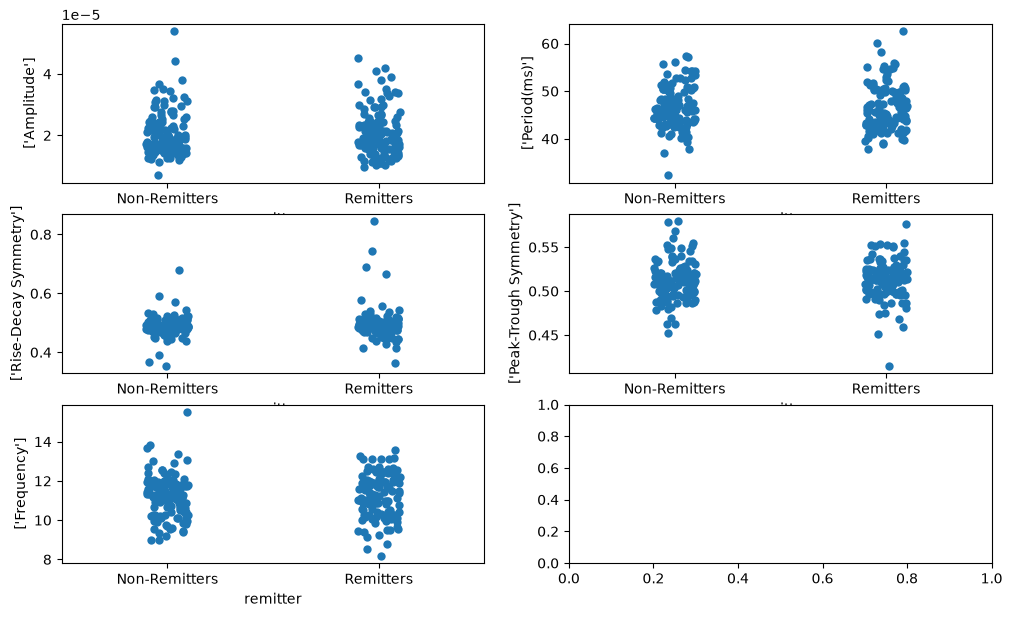

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(12,7))

# amplitude
sns.stripplot(data=summary_eo, x='remitter', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary_eo, x='remitter', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary_eo, x='remitter', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary_eo, x='remitter', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

# frequency 
sns.stripplot(data=summary_eo, x='remitter', y='freq', ax=axes[2][0], size=6, jitter=True)
axes[2][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[2][0].set_ylabel(['Frequency'])

In [ ]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry', 
                 'freq': 'Frequency'}

for feat, feat_name in feature_names.items():

    x_remitter = summary_eo[summary_eo['remitter'] == 1][feat].dropna()
    x_non_remitter = summary_eo[summary_eo['remitter'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_remitter, x_non_remitter)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7353, p=0.85989
Period (ms)          difference between groups, U= 6931, p=0.54741
Rise-Decay Symmetry  difference between groups, U= 7566, p=0.56853
Peak-Trough Symmetry difference between groups, U= 7812, p=0.30540
Frequency            difference between groups, U= 7538, p=0.60413


In [26]:
# responder/non-responder comparison
responders = summary_eo[summary_eo['responder'] == 1]
non_responders = summary_eo[summary_eo['responder'] == 0]

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']

/tmp/ipykernel_1086334/2636933808.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Responders', 'Responders'])
/tmp/ipykernel_1086334/2636933808.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Responders', 'Responders'])
/tmp/ipykernel_1086334/2636933808.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Responders', 'Responders'])
/tmp/ipykernel_1086334/2636933808.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be misl

Text(0, 0.5, "['Frequency']")

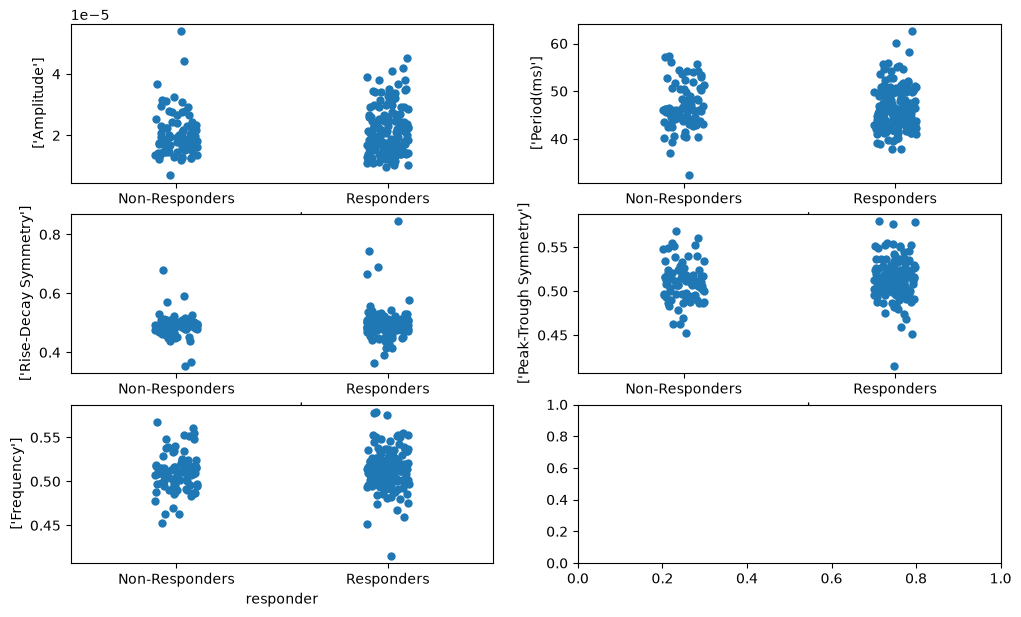

In [27]:
fig, axes = plt.subplots(3, 2, figsize=(12,7))

# amplitude
sns.stripplot(data=summary_eo, x='responder', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Responders', 'Responders'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary_eo, x='responder', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Responders', 'Responders'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary_eo, x='responder', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Responders', 'Responders'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary_eo, x='responder', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Responders', 'Responders'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

#freq
sns.stripplot(data=summary_eo, x='responder', y='time_ptsym', ax=axes[2][0], size=6, jitter=True)
axes[2][0].set_xticklabels(['Non-Responders', 'Responders'])
axes[2][0].set_ylabel(['Frequency'])


In [28]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry',
                 'freq': 'Frequency'}

for feat, feat_name in feature_names.items():

    x_responder = summary_eo[summary_eo['responder'] == 1][feat].dropna()
    x_non_responder = summary_eo[summary_eo['responder'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_responder, x_non_responder)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7135, p=0.36518
Period (ms)          difference between groups, U= 6602, p=0.90482
Rise-Decay Symmetry  difference between groups, U= 6851, p=0.72051
Peak-Trough Symmetry difference between groups, U= 7722, p=0.04158
Frequency            difference between groups, U= 6582, p=0.87358


In [29]:
# applying random forest classifier
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RepeatedStratifiedKFold, cross_validate, cross_val_predict
)

from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay
)
from sklearn.inspection import permutation_importance

In [30]:
# eyes closed data / remitter
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']
X_ec = summary[features]
y_rem_ec = summary['remitter'].astype(int) # either 0 (non remitter) or 1 (remitter)

print(y_rem_ec.value_counts())  # check class balance first (half are non remitters and the other half are remitters)

rf_rem_ec = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=3,        # keeps trees shallow, helps with small n
    class_weight='balanced',   # handles unequal group sizes
    random_state=42,
    n_jobs=-1,
)

# Repeated stratified CV gives a more stable estimate than one split
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

scores_rem_ec = cross_validate(rf_rem_ec, X_ec, y_rem_ec, cv=cv,
                        scoring=['roc_auc', 'balanced_accuracy', 'f1'])
for k in ['test_roc_auc', 'test_balanced_accuracy', 'test_f1']:
    print(f"{k}: {scores_rem_ec[k].mean():.3f} ± {scores_rem_ec[k].std():.3f}")

from sklearn.model_selection import permutation_test_score

score_rem_ec, perm_scores_rem_ec, pval_rem_ec = permutation_test_score(
    rf_rem_ec, X_ec, y_rem_ec, cv=5, scoring='roc_auc', n_permutations=500, random_state=42, n_jobs=-1
)
print(f"EC Remitter: AUC = {score_rem_ec:.3f}, permutation p = {pval_rem_ec:.4f}")


remitter
0    123
1    122
Name: count, dtype: int64


test_roc_auc: 0.514 ± 0.073
test_balanced_accuracy: 0.489 ± 0.060
test_f1: 0.492 ± 0.071


/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the curre

EC Remitter: AUC = 0.535, permutation p = 0.2395


In [31]:
# eyes closed data / responder
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']
X_ec = summary[features]
y_resp_ec = summary['responder'].astype(int) # either 0 (non responder) or 1 (responder)

print(y_resp_ec.value_counts())  # check class balance first 

rf_resp_ec = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=3,        # keeps trees shallow, helps with small n
    class_weight='balanced',   # handles unequal group sizes
    random_state=42,
    n_jobs=-1,
)

# Repeated stratified CV gives a more stable estimate than one split
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

scores_resp_ec = cross_validate(rf_resp_ec, X_ec, y_resp_ec, cv=cv,
                        scoring=['roc_auc', 'balanced_accuracy', 'f1'])
for k in ['test_roc_auc', 'test_balanced_accuracy', 'test_f1']:
    print(f"{k}: {scores_resp_ec[k].mean():.3f} ± {scores_resp_ec[k].std():.3f}")

# permutation score 
score_resp_ec, perm_scores_resp_ec, pval_resp_ec = permutation_test_score(
    rf_resp_ec, X_ec, y_resp_ec, cv=5, scoring='roc_auc', n_permutations=500, random_state=42, n_jobs=-1
)
print(f"EC Responder: AUC = {score_resp_ec:.3f}, permutation p = {pval_resp_ec:.4f}")

responder
1    160
0     85
Name: count, dtype: int64
test_roc_auc: 0.543 ± 0.069
test_balanced_accuracy: 0.522 ± 0.057
test_f1: 0.659 ± 0.053
EC Responder: AUC = 0.540, permutation p = 0.2255


In [32]:
# eyes open data / remitter
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']
X_eo = summary_eo[features]
y_rem_eo = summary_eo['remitter'].astype(int) # either 0 (non remitter) or 1 (remitter)

print(y_rem_eo.value_counts())  # check class balance first (half are non remitters and the other half are remitters)

rf_rem_eo = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=3,        # keeps trees shallow, helps with small n
    class_weight='balanced',   # handles unequal group sizes
    random_state=42,
    n_jobs=-1,
)

# Repeated stratified CV gives a more stable estimate than one split
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

scores_rem_eo = cross_validate(rf_rem_eo, X_eo, y_rem_eo, cv=cv,
                        scoring=['roc_auc', 'balanced_accuracy', 'f1'])
for k in ['test_roc_auc', 'test_balanced_accuracy', 'test_f1']:
    print(f"{k}: {scores_rem_eo[k].mean():.3f} ± {scores_rem_eo[k].std():.3f}")

from sklearn.model_selection import permutation_test_score

score_rem_eo, perm_scores_rem_eo, pval_rem_eo = permutation_test_score(
    rf_rem_eo, X_eo, y_rem_eo, cv=5, scoring='roc_auc', n_permutations=500, random_state=42, n_jobs=-1
)
print(f"EO Remitter: AUC = {score_rem_eo:.3f}, permutation p = {pval_rem_eo:.4f}")

remitter
0    123
1    118
Name: count, dtype: int64
test_roc_auc: 0.458 ± 0.061
test_balanced_accuracy: 0.476 ± 0.061
test_f1: 0.464 ± 0.072
EO Remitter: AUC = 0.437, permutation p = 0.9002


In [33]:
# eyes open data / responder
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'freq']
X_eo = summary_eo[features]
y_resp_eo = summary_eo['responder'].astype(int) # either 0 (non responder) or 1 (responder)

print(y_resp_eo.value_counts())  # check class balance first 

rf_resp_eo = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=3,        # keeps trees shallow, helps with small n
    class_weight='balanced',   # handles unequal group sizes
    random_state=42,
    n_jobs=-1,
)

# Repeated stratified CV gives a more stable estimate than one split
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

scores_resp_eo = cross_validate(rf_resp_eo, X_eo, y_resp_eo, cv=cv,
                        scoring=['roc_auc', 'balanced_accuracy', 'f1'])
for k in ['test_roc_auc', 'test_balanced_accuracy', 'test_f1']:
    print(f"{k}: {scores_resp_eo[k].mean():.3f} ± {scores_resp_eo[k].std():.3f}")

# permutation score 
score_resp_eo, perm_scores_resp_eo, pval_resp_eo = permutation_test_score(
    rf_resp_eo, X_eo, y_resp_eo, cv=5, scoring='roc_auc', n_permutations=500, random_state=42, n_jobs=-1
)
print(f"EO Responder: AUC = {score_resp_eo:.3f}, permutation p = {pval_resp_eo:.4f}")

responder
1    155
0     86
Name: count, dtype: int64
test_roc_auc: 0.519 ± 0.067
test_balanced_accuracy: 0.514 ± 0.062
test_f1: 0.637 ± 0.052


/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the curre

EO Responder: AUC = 0.498, permutation p = 0.5469


In [34]:
summary['age']     = labels.loc[summary.index, 'age']
summary['bdi_pre'] = labels.loc[summary.index, 'BDI_pre']

In [35]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

clin = ['age', 'bdi_pre']
eeg  = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']

feature_cols = clin            # age/BDI alone


target = 'remitter'           

# dropna on ALL columns so both runs use exactly the same subjects
d = summary[clin + eeg + [target]].dropna()
X = d[feature_cols]
y = d[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

base_model = LogisticRegression(max_iter=1000, random_state=42)

param_grid = {"C": [0.01, 0.1, 1.0, 10.0, 100.0], "penalty": ["l2"], "solver": ["lbfgs"]}

grid_search = GridSearchCV(base_model, param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train_scaled, y_train)
best_model = grid_search.best_estimator_

print(f"Features: {feature_cols}")
print(f"n = {len(y)}, test set = {len(y_test)}")
print(f"Best Hyperparameters: {grid_search.best_params_}\n")

y_pred = best_model.predict(X_test_scaled)
y_prob = best_model.predict_proba(X_test_scaled)[:, 1]

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Features: ['age', 'bdi_pre']
n = 218, test set = 44
Best Hyperparameters: {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs'}

Test Accuracy: 0.5909
ROC-AUC Score: 0.6736

Confusion Matrix:
[[14  8]
 [10 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.64      0.61        22
           1       0.60      0.55      0.57        22

    accuracy                           0.59        44
   macro avg       0.59      0.59      0.59        44
weighted avg       0.59      0.59      0.59        44



/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf in

In [36]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

clin = ['age', 'bdi_pre']
eeg  = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']

feature_cols_combined = clin + eeg    # age/BDI + bycycle features
target = 'remitter'            # or 'responder'

# dropna on ALL columns so both runs use exactly the same subjects
d = summary[clin + eeg + [target]].dropna()
X = d[feature_cols_combined]
y = d[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

base_model = LogisticRegression(max_iter=1000, random_state=42)

param_grid = {"C": [0.01, 0.1, 1.0, 10.0, 100.0], "penalty": ["l2"], "solver": ["lbfgs"]}

grid_search = GridSearchCV(base_model, param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train_scaled, y_train)
best_model = grid_search.best_estimator_

print(f"Features: {feature_cols_combined}")
print(f"n = {len(y)}, test set = {len(y_test)}")
print(f"Best Hyperparameters: {grid_search.best_params_}\n")

y_pred = best_model.predict(X_test_scaled)
y_prob = best_model.predict_proba(X_test_scaled)[:, 1]

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Features: ['age', 'bdi_pre', 'volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']
n = 218, test set = 44
Best Hyperparameters: {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs'}

Test Accuracy: 0.6136
ROC-AUC Score: 0.6467

Confusion Matrix:
[[15  7]
 [10 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.68      0.64        22
           1       0.63      0.55      0.59        22

    accuracy                           0.61        44
   macro avg       0.62      0.61      0.61        44
weighted avg       0.62      0.61      0.61        44



/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf in